# Access

> How long it takes to get to Canary Wharf from every street, with and without the tunnel.

A street network is a graph: junctions are nodes, streets are edges, and each edge takes some minutes to travel. The
time from anywhere to Canary Wharf is the shortest path through that graph. The tunnel is one more edge.

Notebook 04 joins these times onto house sales and homes.

In [ ]:
#| default_exp access

In [ ]:
#| export
import geopandas as gpd
import networkx as nx
import numpy as np
import osmnx as ox
import pandas as pd

from tunnel.config import BNG, DERIVED, NORTH_PORTAL, SOUTH_PORTAL, to_bng, tunnel_length_m

In [ ]:
import matplotlib.pyplot as plt
from fastcore.test import test_eq
from shapely.geometry import Point

from tunnel.config import CANARY_WHARF, CYCLE_KMH, FIGURES, LIFT_DELAY_MIN, WALK_KMH, WGS84, use_style
from tunnel.data import stations, street_graph

use_style()

## Shortest paths

Edges are weighted in minutes.

In [ ]:
#| export
def minutes(metres, kmh):
    "Minutes to cover `metres` at `kmh`."
    return metres / (kmh * 1000 / 60)

In [ ]:
test_eq(minutes(800, 4.8), 10)

Here's a toy river crossing. A and D face each other across the water; the only way between them is round by B and
C, ten minutes a side. Nodes carry BNG coordinates, as real ones will.

In [ ]:
toy = nx.Graph()
for n, (x, y) in {"A": (0, 0), "B": (0, 100), "C": (100, 100), "D": (100, 0)}.items():
    toy.add_node(n, x=x, y=y)
toy.add_edges_from([("A", "B"), ("B", "C"), ("C", "D")], minutes=10)

We locate places by their nearest node, and time every node to a destination with Dijkstra's algorithm.

In [ ]:
#| export
def nearest_node(G, xy):
    "The node of `G` closest to BNG point `xy`."
    nodes = list(G.nodes)
    xs, ys = (np.array([G.nodes[n][k] for n in nodes]) for k in ("x", "y"))
    return nodes[int(np.argmin((xs - xy[0]) ** 2 + (ys - xy[1]) ** 2))]


def times_to(G, xy):
    "Minutes from every node of `G` to the node nearest `xy`."
    return pd.Series(nx.single_source_dijkstra_path_length(G, nearest_node(G, xy), weight="minutes"))

In [ ]:
test_eq(nearest_node(toy, (90, 5)), "D")
test_eq(times_to(toy, (100, 0)).to_dict(), {"D": 0, "C": 10, "B": 20, "A": 30})

A crossing is a new edge between the nodes nearest its two ends.

In [ ]:
#| export
def add_link(G, a, b, mins):
    "A copy of `G` with an edge taking `mins` between the nodes nearest BNG points `a` and `b`."
    H = G.copy()
    H.add_edge(nearest_node(G, a), nearest_node(G, b), minutes=mins)
    return H

In [ ]:
test_eq(times_to(add_link(toy, (0, 0), (100, 0), 5), (100, 0))["A"], 5)

The tunnel is that, with the time to walk or ride down one ramp, through the tube and up the other. There are no
lifts to wait for, but the ramps make the trip long: about 940 m from entrance to entrance.

In [ ]:
#| export
def tunnel_minutes(kmh):
    "Minutes from ramp head to ramp head at `kmh`."
    return minutes(tunnel_length_m(), kmh)


def with_tunnel(G, kmh):
    "A copy of `G` with the tunnel added."
    return add_link(G, to_bng(SOUTH_PORTAL), to_bng(NORTH_PORTAL), tunnel_minutes(kmh))

In [ ]:
{f"{kmh} km/h": round(tunnel_minutes(kmh), 1) for kmh in (WALK_KMH, CYCLE_KMH)}

{'4.8 km/h': np.float64(11.8), '15.0 km/h': np.float64(3.8)}

Public transport is approximated as the walk to a station plus a fixed time from that station to Canary Wharf
(riding, half the wait, any change). Everyone picks their best station.

In [ ]:
#| export
def via_stations(G, rides):
    "Minutes from every node of `G` by walking to a station and riding; `rides` maps BNG points to ride minutes."
    return pd.concat([times_to(G, xy) + ride for xy, ride in rides.items()], axis=1).min(axis=1)

In [ ]:
test_eq(via_stations(toy, {(100, 100): 2, (100, 0): 0})["A"], 22)  # walk to C, then ride

## The real networks

OSM's walk and bike networks are directed multigraphs in degrees. We want undirected graphs in metres, weighted in
minutes, keeping the quicker of any parallel edges.

In [ ]:
#| export
def prepare(G, kmh, exclude=()):
    "Undirected BNG graph from an OSM network, weighted in minutes at `kmh`, without streets named in `exclude`."
    G = ox.project_graph(G, to_crs=BNG)
    U = nx.Graph()
    U.add_nodes_from(G.nodes(data=True))
    for u, v, d in G.edges(data=True):
        name = d.get("name", "")
        if any(x in (" / ".join(name) if isinstance(name, list) else str(name)) for x in exclude):
            continue
        m = minutes(d["length"], kmh)
        if not U.has_edge(u, v) or U[u][v]["minutes"] > m:
            U.add_edge(u, v, minutes=m)
    return U

The Rotherhithe road tunnel is legal to walk and cycle but notoriously unpleasant (reportedly about four pedestrians
a day), so we leave it out.

In [ ]:
walk = prepare(street_graph("walk"), WALK_KMH, exclude=["Rotherhithe Tunnel"])
bike = prepare(street_graph("bike"), CYCLE_KMH, exclude=["Rotherhithe Tunnel"])
f"walk: {len(walk):,} nodes, bike: {len(bike):,} nodes"

'walk: 25,957 nodes, bike: 13,931 nodes'

OSM's bike network leaves out the Greenwich foot tunnel, because cyclists must get off and push. Without it
Greenwich and Deptford look cut off, so we add it back at walking pace plus the lifts.

In [ ]:
raw = ox.project_graph(street_graph("walk"), to_crs=BNG)
ends = {n for u, v, d in raw.edges(data=True) if "Greenwich Foot Tunnel" in str(d.get("name", "")) for n in (u, v)}
pts = [Point(raw.nodes[n]["x"], raw.nodes[n]["y"]) for n in ends]
a, b = max(((p, q) for p in pts for q in pts), key=lambda pq: pq[0].distance(pq[1]))
bike = add_link(bike, a.coords[0], b.coords[0], minutes(a.distance(b), WALK_KMH) + 2 * LIFT_DELAY_MIN)
f"Greenwich foot tunnel: {a.distance(b):.0f} m"

'Greenwich foot tunnel: 379 m'

Door-to-door minutes from each station to Canary Wharf, set by hand:

In [ ]:
STATION_MINUTES = {
    "South Quay": 4, "Crossharbour": 5, "Mudchute": 6, "Island Gardens": 8, "Westferry": 5, "Limehouse": 6,
    "Poplar": 5, "All Saints": 7, "Blackwall": 7, "Shadwell": 9, "Tower Gateway": 12, "Whitechapel": 6,
    "Canada Water": 5, "Bermondsey": 7, "North Greenwich": 5, "Canning Town": 7, "Surrey Quays": 12,
    "Rotherhithe": 12, "Wapping": 13, "New Cross Gate": 15, "New Cross": 15, "Queens Road Peckham": 18,
    "Deptford Bridge": 11, "Greenwich": 10, "Cutty Sark for Maritime Greenwich": 9, "Deptford": 20,
    "South Bermondsey": 20,
}  # fmt: skip
st = stations().drop_duplicates("name").set_index("name").loc[list(STATION_MINUTES)].to_crs(BNG)
rides = {(p.x, p.y): STATION_MINUTES[n] for n, p in st.geometry.items()}

## Before and after

For walking and public transport we take whichever is quicker. The tunnel helps public transport too, by bringing
the Isle of Dogs stations within a walk.

In [ ]:
cw = to_bng(CANARY_WHARF)
walk_after, bike_after = with_tunnel(walk, WALK_KMH), with_tunnel(bike, CYCLE_KMH)


def node_frame(G):
    return gpd.GeoDataFrame(
        index=list(G.nodes),
        geometry=gpd.points_from_xy(*zip(*((d["x"], d["y"]) for _, d in G.nodes(data=True)))),
        crs=BNG,
    )


nodes = node_frame(walk).assign(
    walk_before=times_to(walk, cw), walk_after=times_to(walk_after, cw),
    pt_before=via_stations(walk, rides), pt_after=via_stations(walk_after, rides),
)  # fmt: skip
nodes["access_before"] = nodes[["walk_before", "pt_before"]].min(axis=1)
nodes["access_after"] = nodes[["walk_after", "pt_after"]].min(axis=1)
nodes = nodes.dropna(subset=["access_before"])
bike_nodes = node_frame(bike).assign(cycle_before=times_to(bike, cw), cycle_after=times_to(bike_after, cw)).dropna()

nodes.to_file(DERIVED / "access_nodes.gpkg", layer="walk_pt", driver="GPKG")
bike_nodes.to_file(DERIVED / "access_nodes.gpkg", layer="cycle", driver="GPKG")

Anything else can now look up its travel times from the nearest node.

In [ ]:
#| export
ACCESS_COLS = ["walk_before", "walk_after", "pt_before", "pt_after", "access_before", "access_after"]
CYCLE_COLS = ["cycle_before", "cycle_after"]


def attach_access(points):
    "`points` (returned in BNG) with before/after travel times from their nearest street node."
    pts = points.to_crs(BNG)
    for layer, cols in (("walk_pt", ACCESS_COLS), ("cycle", CYCLE_COLS)):
        nodes = gpd.read_file(DERIVED / "access_nodes.gpkg", layer=layer)[cols + ["geometry"]]
        pts = gpd.sjoin_nearest(pts, nodes, how="left").drop(columns="index_right")
        pts = pts[~pts.index.duplicated()]  # equidistant ties
    return pts

In [ ]:
places = gpd.GeoDataFrame(
    {"place": ["Nelson Dock (south portal)", "Surrey Docks Farm", "Greenland Dock", "Canada Water station", "Deptford High Street"]},
    geometry=[Point(SOUTH_PORTAL), Point(-0.03343, 51.49959), Point(-0.03960, 51.49465), Point(-0.04910, 51.49847), Point(-0.02600, 51.47507)],
    crs=WGS84,
)  # fmt: skip
check = attach_access(places).set_index("place")[["access_before", "access_after", "cycle_before", "cycle_after"]]
portal = check.loc["Nelson Dock (south portal)"]
test_eq(portal.access_after < portal.access_before and portal.cycle_after < portal.cycle_before, True)
check.round(1)

,access_before,access_after,cycle_before,cycle_after
place,,,,
Nelson Dock (south portal),32.6,19.9,35.1,9.8
Surrey Docks Farm,28.9,27.7,35.5,13.3
Greenland Dock,23.4,23.4,34.1,15.1
Canada Water station,6.6,6.6,30.1,16.8
Deptford High Street,21.5,21.5,31.2,26.8


The tunnel helps most near the Rotherhithe portal, and far more by bike than on foot: walking the ramps and the tube
takes about twelve minutes, but cycling them takes under four. Places with a station of their own, like
Canada Water, gain nothing.

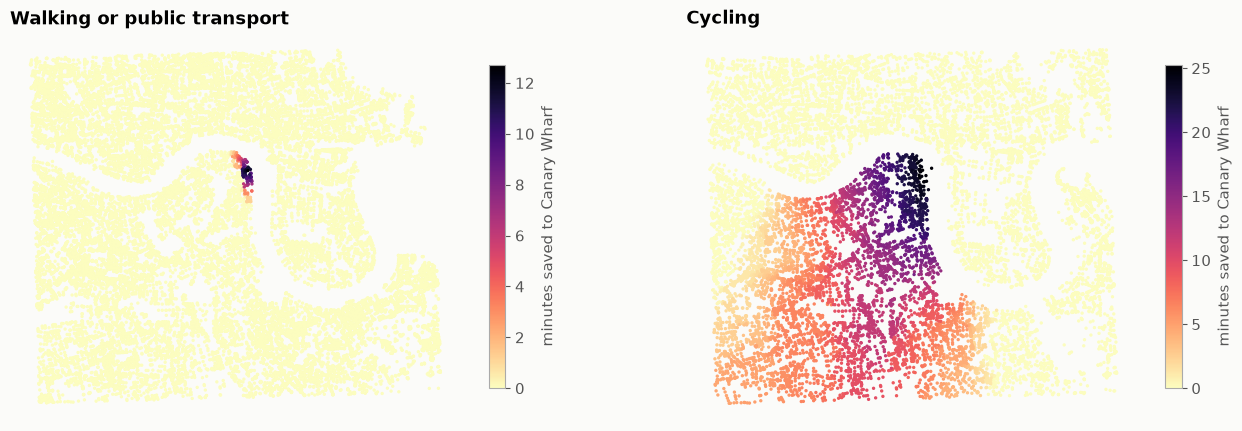

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (gdf, col, title) in zip(
    axes, [(nodes, "access", "Walking or public transport"), (bike_nodes, "cycle", "Cycling")]
):
    saved = (gdf[f"{col}_before"] - gdf[f"{col}_after"]).clip(lower=0)
    gdf.assign(saved=saved).sort_values("saved").plot(
        ax=ax, column="saved", cmap="magma_r", markersize=2, legend=True, vmin=0,
        legend_kwds={"label": "minutes saved to Canary Wharf", "shrink": 0.6},
    )  # fmt: skip
    ax.set_title(title, fontsize=13)
    ax.set_axis_off()
fig.savefig(FIGURES / "minutes_saved.png")